In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

In [ ]:
x = pd.read_csv("0_x.csv", header=None)
y = pd.read_csv("0_y.csv", header=None)

In [ ]:
y

,0
0,63.320498
1,-23.426394
2,11.982771
3,-102.883304
4,-49.373475
...,...
382,200.741686
383,208.530827
384,132.592022
385,-248.134498


In [ ]:
x

,0,1,2,3,4
0,0.071841,0.855352,-0.305597,0.028253,1.826895
1,0.139521,-0.423507,0.461059,-0.447400,-0.034988
2,1.626311,-0.257622,-0.697520,1.413219,1.086292
3,-1.183233,-0.826343,0.073047,-0.639690,-0.503273
4,-0.783365,-0.861232,0.951448,-0.117306,0.680597
...,...,...,...,...,...
382,0.684004,2.320728,0.380965,-1.050408,-0.151801
383,-0.430455,2.097191,0.379874,0.135858,-1.400176
384,-0.457141,0.940791,-0.660270,2.325658,-1.510055
385,-0.344278,-1.209805,-2.119721,-1.485907,-0.167689


In [ ]:
print(x.shape)
print(y.shape)

(387, 5)
(387, 1)


# **Задача 2**

In [ ]:
#Реализуем метод градиентного спуска в модели множественной регрессии
class MultipleRegression(object):
    def __init__(self):
        self.b = None
    def predict(self, x):
        return x @ self.b
    def MSE(self, x, y):
        return (((y - self.predict(x)).T @ (y - self.predict(x))) / (2 * x.shape[0])).values
    def MAE(self, x, y):
        return (abs(y - self.predict(x)).mean()).values
    def MAPE(self, x, y):
        return (abs((y - self.predict(x))/y).mean()).values
    def coefs(self):
        return self.b
    def fit(self, x, y, alpha = 0.1, accuracy = 0.1, max_steps = 10000, intercept = True):
        y = np.array(y).reshape(-1, 1)
        if intercept:
            x['intercept'] = 1
        self.b = np.zeros((x.shape[1], 1))
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dJ_b = x.T @ (self.predict(x) - y) / x.shape[0]
            self.b -= alpha * dJ_b
            new_error = self.MSE(x, y)
            step += 1
            steps.append(step)
            errors.append(new_error)
        return steps, errors

In [ ]:
regr = MultipleRegression()
x_ = x.copy()
steps, errors = regr.fit(x, y, alpha = 0.01, accuracy = 0.01, max_steps = 1000, intercept = True)

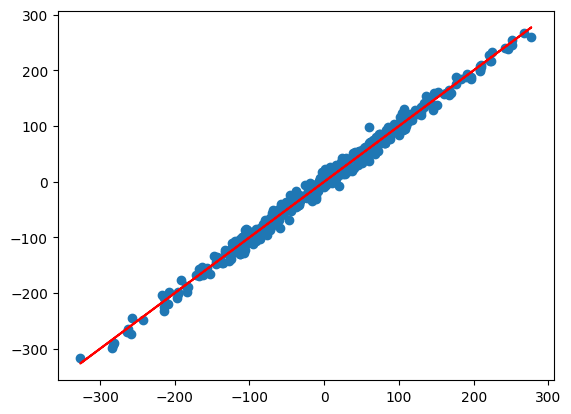

In [ ]:
yy = regr.predict(x)
plt.scatter(yy, y)
plt.plot(yy, yy, c='r')

In [ ]:
print(regr.MAE(x, y))

[7.78050547]


In [ ]:
print(regr.MSE(x, y))

[[46.74619396]]


In [ ]:
regr.MAPE(x, y)

array([0.33301842])

# **Задачи 3, 5 и 6**
# полиномиальная регрессия для всех признаков

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [ ]:
poly_features = PolynomialFeatures(degree=10).fit_transform(x)

In [ ]:
poly_reg_model = LinearRegression()
start_time = time.time()
poly_reg_model.fit(poly_features, y)
print('Время обучения: ', time.time() - start_time, 'сек.')
start_time

Время обучения:  0.6699802875518799 сек.


1698170790.364294

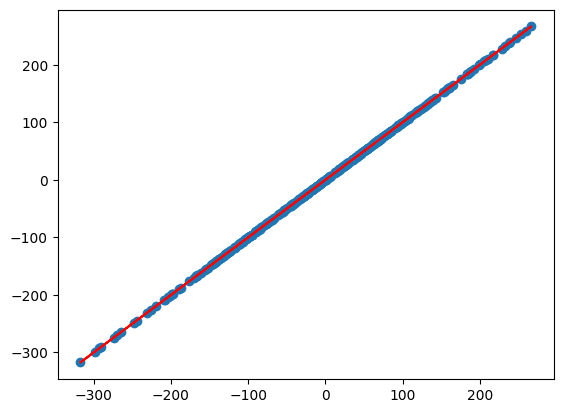

In [ ]:
yy = poly_reg_model.predict(poly_features)
plt.scatter(yy, y)
plt.plot(yy, yy, c='r')

In [ ]:
poly_reg_model.score(poly_features, y)

In [ ]:
poly_reg_model.score(poly_features, y)

In [ ]:
poly_reg_model.score(poly_features, y)

# **Задачи 3, 5 и 6**
# полиномиальная регрессия для каждого признака

In [ ]:
degrees = [2, 3, 10]
for column in x.columns:
  x_i = x[[column]]
  for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    x_poly = poly.fit_transform(x_i)

    model = LinearRegression()
    model.fit(x_poly, y)
    y_pred = model.predict(x_poly)

    print(f'Pol regression {degree} for column: {column}')

    plt.scatter(x_i, y)
    plt.xlabel(f'column: {column}')
    plt.ylabel('Target Variable')

    sorted_indices = np.argsort(x_i.values[:, 0])
    x_sorted = x_i.values[sorted_indices]
    y_sorted_pred = y_pred[sorted_indices]

    plt.plot(x_sorted, y_sorted_pred, c= 'r',label=f'degree{degree}')
    plt.legend()
    plt.show()

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error

results = []
for i in range(11):
  start = time.time()

  poly = PolynomialFeatures(degree = i)
  X_poly = poly.fit_transform(x)
  model = LinearRegression()
  model.fit(X_poly, y)
  y_pred = model.predict(X_poly)

  duration = time.time() - start
  score = model.score(X_poly, y)
  mse = mean_squared_error(y_pred, y)

  results.append([i, duration, score, mse])

  plt.scatter(y_pred, y)
  plt.plot(y, y, c = 'r')
  plt.title(f"Degree {i}")
  plt.show()

In [ ]:
df = pd.DataFrame(results, columns = ["Degree", "Duration", "Model_Score", "MSE"])
print(df)